# 🎯 Sistem Analisis Sentimen — Nowhere Experience Batam
ANALISIS SENTIMEN TERHADAP PROMOSI NOWHERE EXPERIENCE DI MEDIA SOSIAL MENGGUNAKAN METODE NAIVE BAYES

**Algoritma:** Multinomial Naive Bayes  
**Objek Analisis:** Nowhere Experience Batam (Escape Room)  
**Kelas Sentimen:** Positif, Negatif, Netral  

Notebook ini berisi pipeline lengkap NLP: generate dataset → preprocessing → TF-IDF → training Naive Bayes → evaluasi → prediksi → visualisasi.

---

## 【Cell 1】Instalasi Library

In [ ]:
!pip install sastrawi -q
print("=" * 60)
print("Sastrawi berhasil di-install")
print("=" * 60)

Sastrawi berhasil di-install


## 【Cell 2】Import Library

In [ ]:
import pandas as pd
import numpy as np
import re
import string
import random
import warnings

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
from sklearn.pipeline import Pipeline

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
random.seed(42)
np.random.seed(42)

print("=" * 60)
print("Semua library berhasil di-import")
print("=" * 60)

Semua library berhasil di-import


## 【Cell 3】Generate Dataset (~1000 data)

In [ ]:
random.seed(42)

positif_templates = [
    "seru banget main di nowhere experience batam",
    "puzzle nya menantang dan bikin penasaran",
    "dekorasi room keren parah",
    "tempatnya bagus dan nyaman",
    "staff nya ramah dan helpful",
    "recommended banget untuk yang suka escape room",
    "worth it banget harga sama pengalaman",
    "pengalaman tak terlupakan bareng teman",
    "misteri nya menarik dan bikin penasaran",
    "tema room nya kreatif dan beda dari yang lain",
    "good place buat healing akhir pekan",
    "fun experience bareng keluarga",
    "will come back lagi next time",
    "keluarga senang sekali main di sini",
    "tim kerja bonding makin solid",
    "game master helpful dan sabar",
    "petunjuk jelas dan mudah dipahami",
    "suasana tegang tapi seru",
    "foto spot bagus buat instagram",
    "harga sebanding dengan kualitas",
    "best escape room di batam so far",
    "pelayanan cepat dan ramah",
    "room design detail dan estetik",
    "bikin ketagihan mau coba room lain",
    "audio efek nya bikin mimpi realistis",
]

negatif_templates = [
    "puzzle terlalu sulit tidak masuk akal",
    "petunjuk tidak jelas bikin bingung",
    "ruangan sempit tidak bisa gerak",
    "panas banget di dalam room",
    "mahal banget untuk pengalaman begini",
    "tidak worth it uang keluar banyak",
    "mengecewakan sekali pengalaman kali ini",
    "lama banget respon game master",
    "booking susah sistemnya ribet",
    "ac tidak dingin gerah parah",
    "gelap banget tidak nyaman mata sakit",
    "staff kurang ramah canggung",
    "room berantakan props keluar tempat",
    "props rusak tidak bisa dipakai",
    "tidak sesuai ekspektasi dari review",
    "waktu terbuang sia-sia",
    "skip aja mending cari tempat lain",
    "jangan datang ke sini kalau bisa",
    "regret banget udah bayar mahal",
    "pelayanan lambat tidak profesional",
    "suasana tidak tegang sama sekali",
    "room terlalu mudah selesai cepat",
    "audio jelek tidak kedengaran jelas",
    "bau tidak sedap di dalam room",
    "toilet kotor tidak terawat",
]

netral_templates = [
    "biasa aja sih menurut saya",
    "lumayan lah buat sekali coba",
    "cukup standar escape room",
    "tidak terlalu spesial sih",
    "normal lah seperti escape room lain",
    "sesuai harga lah ya",
    "pelayanan biasa saja tidak istimewa",
    "konsep standar escape room gitu",
    "pernah coba yang lebih baik",
    "tidak buruk juga lah",
    "oke lah sesuai ekspektasi",
    "biasa-biasa saja tidak ada yang menonjol",
    "so so nothing special",
    "average experience for the price",
    "could be better tapi lumayan",
    "biasa kalau sudah pernah main escape room lain",
    "menengah saja tidak terlalu bagus tidak terlalu buruk",
    "standar bawaan escape room pada umumnya",
    "fair enough buat pemula",
    "tidak ada yang wah buat saya",
]

fillers = ["sih", "kok", "yah", "nah", "gitu", "dong", "kan", "deh", "lah", "ya", "loh", "tuh"]
openers = ["wah", "hmm", "btw", "ya", "eh", "so", "tapi", "dan", "tapi ya"]
typos = {"banget": "bgt", "sangat": "bgt", "tidak": "gak", "tetapi": "tp", "tapi": "tp",
         "dengan": "dgn", "juga": "jg", "sudah": "udh", "lagi": "lg",
         "karena": "krn", "sampai": "smpe", "bisa": "bsa"}
emoticons_pos = [":)", ":D", ":))", ":-)", "^^"]
emoticons_neg = [":(", ":-(", ":\'(", ":/"]


def add_noise(text):
    """Tambahkan noise ringan: spasi berlebih, kapital acak, tanda baca berlebih."""

    if random.random() < 0.15:
        text = text.replace(" ", "  ", 1)

    if random.random() < 0.20:
        words = text.split()
        if len(words) > 2:
            idx = random.randint(0, len(words) - 1)
            if words[idx]:
                words[idx] = words[idx][0].upper() + words[idx][1:]
            text = " ".join(words)

    if random.random() < 0.18:
        text = text + random.choice(["!", "!!", "...", "!!!", "."])
    return text


def apply_typos(text):
    """Ganti beberapa kata dengan singkatan/typo."""
    words = text.split()
    out = []
    for w in words:
        if w in typos and random.random() < 0.45:
            out.append(typos[w])
        else:
            out.append(w)
    return " ".join(out)


def build_text(template, sentiment):
    """Bangun 1 kalimat ulasan dari template + filler + opener + emoticon + noise."""
    parts = []

    if random.random() < 0.35:
        parts.append(random.choice(openers))

    parts.append(template)
    if random.random() < 0.25:

        if sentiment == "Positif":
            parts.append(random.choice(positif_templates))
        elif sentiment == "Negatif":
            parts.append(random.choice(negatif_templates))
        else:
            parts.append(random.choice(netral_templates))

    if random.random() < 0.55:
        parts.append(random.choice(fillers))
    text = " ".join(parts)

    if random.random() < 0.55:
        text = apply_typos(text)

    if random.random() < 0.40:
        if sentiment == "Positif":
            text += " " + random.choice(emoticons_pos)
        elif sentiment == "Negatif":
            text += " " + random.choice(emoticons_neg)

    text = add_noise(text)

    if random.random() < 0.30:
        text = "nowhere experience batam " + text
    return text.strip()



n_positif = 400 + random.randint(-10, 10)
n_negatif = 300 + random.randint(-10, 10)
n_netral  = 300 + random.randint(-10, 10)

teks_list = []
label_list = []
seen = set()

for _ in range(n_positif):
    t = build_text(random.choice(positif_templates), "Positif")
    if t in seen:
        t = t + " " + str(random.randint(1, 9999))
    seen.add(t)
    teks_list.append(t)
    label_list.append("Positif")

for _ in range(n_negatif):
    t = build_text(random.choice(negatif_templates), "Negatif")
    if t in seen:
        t = t + " " + str(random.randint(1, 9999))
    seen.add(t)
    teks_list.append(t)
    label_list.append("Negatif")

for _ in range(n_netral):
    t = build_text(random.choice(netral_templates), "Netral")
    if t in seen:
        t = t + " " + str(random.randint(1, 9999))
    seen.add(t)
    teks_list.append(t)
    label_list.append("Netral")


combined = list(zip(teks_list, label_list))
random.shuffle(combined)
teks_list, label_list = zip(*combined)

df = pd.DataFrame({"teks": teks_list, "sentimen": label_list})
df = df.reset_index(drop=True)

print("=" * 60)
print("DATASET SINTETIS BERHASIL DIBUAT")
print("=" * 60)
print(f"Total data         : {len(df)} baris")
print(f"Distribusi label   :")
print(df['sentimen'].value_counts())
print(f"Jumlah duplikat    : {df.duplicated().sum()}")
print("=" * 60)


print("\n10 Sampel Acak Dataset:")
display(df.sample(10, random_state=42))


df.to_csv("dataset_nowhere_batam.csv", index=False, encoding="utf-8-sig")
print(f"\nDataset disimpan ke: dataset_nowhere_batam.csv")

DATASET SINTETIS BERHASIL DIBUAT
Total data         : 993 baris
Distribusi label   :
sentimen
Positif    410
Negatif    293
Netral     290
Name: count, dtype: int64
Jumlah duplikat    : 0

10 Sampel Acak Dataset:


,teks,sentimen
918,gelap banget tidak nyaman mata sakit nah 8445,Negatif
525,nowhere experience batam btw jangan datang ke ...,Negatif
567,nowhere experience batam hmm pengalaman tak t...,Positif
656,foto spot bagus buat instagram gitu,Positif
915,nowhere experience batam gak sesuai ekspektasi...,Negatif
429,nowhere experience batam gelap banget tidak ny...,Negatif
855,harga sebanding dgn kualitas tema room nya kre...,Positif
711,misteri nya menarik dan bikin penasaran kok :-),Positif
174,nowhere experience batam pelayanan biasa saja...,Netral
604,nowhere experience batam hmm dekorasi room ker...,Positif



Dataset disimpan ke: dataset_nowhere_batam.csv


## 【Cell 4】Preprocessing Text

In [ ]:
stemmer_factory = StemmerFactory()
stemmer = stemmer_factory.create_stemmer()

stopword_factory = StopWordRemoverFactory()
stopword_remover = stopword_factory.create_stop_word_remover()
stopword_list = set(stopword_factory.get_stop_words())

print(f"Jumlah stopword Sastrawi: {len(stopword_list)}")
print(f"Contoh stopword: {list(stopword_list)[:10]}")


def preprocessing_text(teks):
    """
    Pipeline preprocessing untuk teks Bahasa Indonesia:
    1. Case folding -> lowercase
    2. Hapus URL
    3. Hapus mention (@user)
    4. Hapus hashtag (#tag)
    5. Hapus semua angka
    6. Hapus tanda baca & karakter spesial
    7. Hapus whitespace berlebih
    8. Tokenisasi (split)
    9. Stopword removal (Sastrawi)
   10. Stemming (Sastrawi)
   11. Join kembali menjadi string
    """
    if not isinstance(teks, str):
        return ""


    teks = teks.lower()


    teks = re.sub(r"http\S+|www\.\S+", " ", teks)

    teks = re.sub(r"@\w+", " ", teks)


    teks = re.sub(r"#\w+", " ", teks)


    teks = re.sub(r"\d+", " ", teks)


    teks = teks.translate(str.maketrans("", "", string.punctuation))
    teks = re.sub(r"[^a-z\s]", " ", teks)


    teks = re.sub(r"\s+", " ", teks).strip()


    tokens = teks.split()
    if not tokens:
        return ""
    teks_joined = " ".join(tokens)


    teks_joined = stopword_remover.remove(teks_joined)


    teks_joined = stemmer.stem(teks_joined)


    teks_joined = re.sub(r"\s+", " ", teks_joined).strip()
    return teks_joined



print("\nMemulai preprocessing (mungkin butuh ~30-60 detik)...")
df["teks_bersih"] = df["teks"].apply(preprocessing_text)
print("Preprocessing selesai!\n")


print("=" * 80)
print("CONTOH BEFORE / AFTER PREPROCESSING")
print("=" * 80)
sample_idx = df.sample(5, random_state=7).index
for i, idx in enumerate(sample_idx, 1):
    print(f"\n--- Contoh {i} ---")
    print(f"BEFORE : {df.loc[idx, 'teks']}")
    print(f"AFTER  : {df.loc[idx, 'teks_bersih']}")
    print(f"LABEL  : {df.loc[idx, 'sentimen']}")
print("\n" + "=" * 80)

Jumlah stopword Sastrawi: 123
Contoh stopword: ['telah', 'kemana', 'juga', 'belum', 'sementara', 'tanpa', 'sebagai', 'toh', 'setelah', 'agak']

Memulai preprocessing (mungkin butuh ~30-60 detik)...
Preprocessing selesai!

CONTOH BEFORE / AFTER PREPROCESSING

--- Contoh 1 ---
BEFORE : props rusak tidak Bisa dipakai yah
AFTER  : props rusak bisa pakai yah
LABEL  : Negatif

--- Contoh 2 ---
BEFORE : puzzle nya menantang dan bikin penasaran yah
AFTER  : puzzle nya tantang bikin penasaran yah
LABEL  : Positif

--- Contoh 3 ---
BEFORE : puzzle terlalu sulit gak masuk akal puzzle terlalu sulit tidak masuk akal Loh
AFTER  : puzzle terlalu sulit gak masuk akal puzzle terlalu sulit masuk akal loh
LABEL  : Negatif

--- Contoh 4 ---
BEFORE : nowhere experience batam pelayanan lambat gak profesional regret banget udah bayar mahal :'(
AFTER  : nowhere experience batam layan lambat gak profesional regret banget udah bayar mahal
LABEL  : Negatif

--- Contoh 5 ---
BEFORE : audio efek nya bikin mimpi re

## 【Cell 5】Feature Extraction (TF-IDF)

In [ ]:
vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

X_tfidf = vectorizer.fit_transform(df["teks_bersih"])
y = df["sentimen"].values

print("=" * 60)
print("TF-IDF MATRIX")
print("=" * 60)
print(f"Shape (n_dokumen, n_fitur) : {X_tfidf.shape}")
print(f"Jumlah fitur total         : {len(vectorizer.get_feature_names_out())}")
print(f"Density (non-zero ratio)   : {X_tfidf.nnz / (X_tfidf.shape[0] * X_tfidf.shape[1]):.4f}")
print("=" * 60)


feature_names = vectorizer.get_feature_names_out()
idf_scores = vectorizer.idf_
feat_idf_df = pd.DataFrame({"fitur": feature_names, "idf": idf_scores})
feat_idf_df = feat_idf_df.sort_values("idf", ascending=False).reset_index(drop=True)

print("\n10 Fitur dengan IDF Tertinggi (term paling unik/diskriminatif):")
display(feat_idf_df.head(10))

TF-IDF MATRIX
Shape (n_dokumen, n_fitur) : (993, 715)
Jumlah fitur total         : 715
Density (non-zero ratio)   : 0.0177

10 Fitur dengan IDF Tertinggi (term paling unik/diskriminatif):


,fitur,idf
0,yang wah,6.803125
1,yang tim,6.803125
2,yang kan,6.803125
3,wah booking,6.803125
4,umum tuh,6.803125
5,umum nah,6.803125
6,umum kok,6.803125
7,umum dong,6.803125
8,tonjol konsep,6.803125
9,tp room,6.803125


## 【Cell 6】Split Data & Training Model

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=" * 60)
print("PEMBAGIAN DATA")
print("=" * 60)
print(f"Data train : {X_train.shape[0]} baris")
print(f"Data test  : {X_test.shape[0]} baris")
print(f"Distribusi train:\n{pd.Series(y_train).value_counts()}\n")
print(f"Distribusi test :\n{pd.Series(y_test).value_counts()}")
print("=" * 60)

model = MultinomialNB(alpha=0.1)
model.fit(X_train, y_train)

print("\nModel MultinomialNB berhasil di-training!")
print(f"   Classes          : {model.classes_}")
print(f"   Alpha (smoothing): {model.alpha}")
print(f"   Jumlah fitur     : {X_train.shape[1]}")

PEMBAGIAN DATA
Data train : 794 baris
Data test  : 199 baris
Distribusi train:
Positif    328
Negatif    234
Netral     232
Name: count, dtype: int64

Distribusi test :
Positif    82
Negatif    59
Netral     58
Name: count, dtype: int64

Model MultinomialNB berhasil di-training!
   Classes          : ['Negatif' 'Netral' 'Positif']
   Alpha (smoothing): 0.1
   Jumlah fitur     : 715


## 【Cell 7】Evaluasi Model

EVALUASI MODEL PADA DATA TEST
Accuracy: 1.0000  (100.00%)

Classification Report:
              precision    recall  f1-score   support

     Negatif     1.0000    1.0000    1.0000        59
      Netral     1.0000    1.0000    1.0000        58
     Positif     1.0000    1.0000    1.0000        82

    accuracy                         1.0000       199
   macro avg     1.0000    1.0000    1.0000       199
weighted avg     1.0000    1.0000    1.0000       199


Confusion Matrix (Angka Mentah):


,Pred_Negatif,Pred_Netral,Pred_Positif
Actual_Negatif,59,0,0
Actual_Netral,0,58,0
Actual_Positif,0,0,82


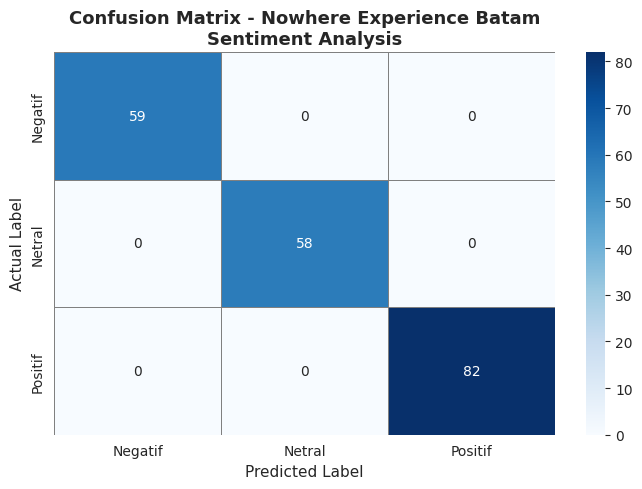


ANALISIS SINGKAT
Semua kelas memiliki F1-score yang sama: 1.0000
Model performanya seimbang di semua kelas.
Accuracy total : 100.00%


In [ ]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

acc = accuracy_score(y_test, y_pred)
print("=" * 60)
print("EVALUASI MODEL PADA DATA TEST")
print("=" * 60)
print(f"Accuracy: {acc:.4f}  ({acc*100:.2f}%)")
print("=" * 60)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

labels_order = list(model.classes_)
cm = confusion_matrix(y_test, y_pred, labels=labels_order)
cm_df = pd.DataFrame(cm, index=[f"Actual_{l}" for l in labels_order],
                     columns=[f"Pred_{l}" for l in labels_order])
print("\nConfusion Matrix (Angka Mentah):")
display(cm_df)


plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_order, yticklabels=labels_order,
            cbar=True, linewidths=0.5, linecolor="gray")
plt.title("Confusion Matrix - Nowhere Experience Batam\nSentiment Analysis",
          fontsize=13, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("Actual Label", fontsize=11)
plt.tight_layout()
plt.show()


report_dict = classification_report(y_test, y_pred, output_dict=True)
f1_scores = {k: report_dict[k]["f1-score"] for k in labels_order}
best_class = max(f1_scores, key=f1_scores.get)
worst_class = min(f1_scores, key=f1_scores.get)
all_equal = len(set(f1_scores.values())) == 1

print("\n" + "=" * 60)
print("ANALISIS SINGKAT")
print("=" * 60)
if all_equal:
    print(f"Semua kelas memiliki F1-score yang sama: {f1_scores[best_class]:.4f}")
    print("Model performanya seimbang di semua kelas.")
else:
    print(f"Kelas TERBAIK  : {best_class}  (F1-score = {f1_scores[best_class]:.4f})")
    print(f"Kelas TERBURUK : {worst_class} (F1-score = {f1_scores[worst_class]:.4f})")
print(f"Accuracy total : {acc*100:.2f}%")
print("=" * 60)

## 【Cell 8】Fungsi Prediksi Sentimen Baru

In [ ]:
def predict_sentimen(teks_input, model, vectorizer, stemmer, stopword_remover):
    """
    Menerima 1 string teks mentah, melakukan preprocessing lengkap,
    TF-IDF transform, lalu prediksi kelas + confidence score.

    Return:
        dict dengan keys:
        - "sentimen"      : label kelas (str)
        - "confidence"    : probabilitas tertinggi (float)
        - "probabilities" : dict {Positif: x, Negatif: y, Netral: z}
    """

    teks_bersih = preprocessing_text(teks_input)


    vec = vectorizer.transform([teks_bersih])


    kelas_pred = model.predict(vec)[0]
    proba = model.predict_proba(vec)[0]
    classes = model.classes_


    probabilities = {str(cls): float(p) for cls, p in zip(classes, proba)}
    confidence = float(max(proba))

    return {
        "sentimen": str(kelas_pred),
        "confidence": round(confidence, 4),
        "probabilities": {k: round(v, 4) for k, v in probabilities.items()},
        "teks_bersih": teks_bersih
    }



demo = predict_sentimen("main di nowhere experience batam seru banget, puzzle menantang!",
                        model, vectorizer, stemmer, stopword_remover)
print("Sanity check fungsi predict_sentimen():")
print(f"Input    : main di nowhere experience batam seru banget, puzzle menantang!")
print(f"Output   : {demo}")

Sanity check fungsi predict_sentimen():
Input    : main di nowhere experience batam seru banget, puzzle menantang!
Output   : {'sentimen': 'Positif', 'confidence': 0.9989, 'probabilities': {'Negatif': 0.0008, 'Netral': 0.0003, 'Positif': 0.9989}, 'teks_bersih': 'main nowhere experience batam seru banget puzzle tantang'}


## 【Cell 9】Demo Interaktif Prediksi

In [ ]:
contoh_teks = [
    # --- 4 contoh POSITIF ---
    "Wah main di Nowhere Experience Batam kemarin seru parah, room-nya bener-bener bikin penasaran sampai akhir!",
    "Recommended banget tempatnya, harga sebanding sama kualitas puzzle yang menantang, akan balik lagi.",
    "Game master-nya helpful dan sabar banget ngasih petunjuk, suasananya tegang tapi seru. Worth it!",
    "Foto spot-nya bagus-bagus, dekorasi room kreatif dan detail, keluarga senang banget main di sini.",

    # --- 3 contoh NEGATIF ---
    "Kecewa berat, AC-nya gak dingin jadi gerah, ruangan sempit, staff kurang ramah. Mahal banget.",
    "Puzzle-nya terlalu sulit gak masuk akal, petunjuk tidak jelas, waktu terbuang sia-sia. Regret!",
    "Booking susah, respon game master lama, props banyak yang rusak. Skip aja mending cari tempat lain.",

    # --- 2 contoh NETRAL ---
    "Biasa aja sih menurut saya, standar escape room pada umumnya, tidak ada yang menonjol tapi tidak buruk juga.",
    "Lumayan lah buat sekali coba, sesuai harga, pelayanan biasa saja. Could be better tapi oke lah.",

    # --- 2 contoh TRICKY (sarkasme + double negation/campuran sentimen) ---
    # Tricky #1: sarkasme (kata positif dalam konteks negatif)
    "Bagus banget katanya puzzle menantang, ternyata gak jelas petunjuknya dan AC panas, mantap deh kecewa",
    # Tricky #2: campuran sentimen (positif di awal, negatif di akhir)
    "Puzzle dan dekorasi room-nya sebenarnya kreatif dan seru, tapi sayang AC panas dan staff lambat respon.",
]
expected_sentiment = [
    "Positif", "Positif", "Positif", "Positif",
    "Negatif", "Negatif", "Negatif",
    "Netral", "Netral",
    "Negatif (sarkasme)",
    "Negatif (campuran)"
]

hasil_list = []
for teks in contoh_teks:
    res = predict_sentimen(teks, model, vectorizer, stemmer, stopword_remover)
    row = {
        "Teks (input)": teks,
        "Teks Bersih": res["teks_bersih"],
        "Prediksi Sentimen": res["sentimen"],
        "Confidence": res["confidence"],
        "P(Positif)": res["probabilities"].get("Positif", 0.0),
        "P(Negatif)": res["probabilities"].get("Negatif", 0.0),
        "P(Netral)": res["probabilities"].get("Netral", 0.0),
    }
    hasil_list.append(row)

hasil_df = pd.DataFrame(hasil_list)
hasil_df.insert(0, "Ekspektasi", expected_sentiment)

# Styling: tampilkan dengan format rapi
print("=" * 90)
print("DEMO PREDIKSI SENTIMEN - Nowhere Experience Batam")
print("=" * 90)
display(hasil_df)
print("=" * 90)
print("Catatan:")
print("  - Baris ke-10: contoh SARKASME (kata positif tapi konteks negatif).")
print("  - Baris ke-11: contoh CAMPURAN SENTIMEN (positif di awal, negatif di akhir).")
print("  Perhatikan bagaimana model menangani ambiguitas tersebut.")
print("=" * 90)

DEMO PREDIKSI SENTIMEN - Nowhere Experience Batam


,Ekspektasi,Teks (input),Teks Bersih,Prediksi Sentimen,Confidence,P(Positif),P(Negatif),P(Netral)
0,Positif,Wah main di Nowhere Experience Batam kemarin s...,wah main nowhere experience batam kemarin seru...,Positif,0.9995,0.9995,0.0003,0.0002
1,Positif,"Recommended banget tempatnya, harga sebanding ...",recommended banget tempat harga banding sama k...,Positif,0.9995,0.9995,0.0005,0.0000
2,Positif,Game master-nya helpful dan sabar banget ngasi...,game master helpful sabar banget ngasih tunjuk...,Positif,0.9963,0.9963,0.0037,0.0000
3,Positif,"Foto spot-nya bagus-bagus, dekorasi room kreat...",foto spotnya bagusbagus dekorasi room kreatif ...,Positif,1.0000,1.0000,0.0000,0.0000
4,Negatif,"Kecewa berat, AC-nya gak dingin jadi gerah, ru...",kecewa berat acnya gak dingin jadi gerah ruang...,Negatif,1.0000,0.0000,1.0000,0.0000
5,Negatif,"Puzzle-nya terlalu sulit gak masuk akal, petun...",puzzlenya terlalu sulit gak masuk akal tunjuk ...,Negatif,1.0000,0.0000,1.0000,0.0000
6,Negatif,"Booking susah, respon game master lama, props ...",booking susah respon game master lama props ba...,Negatif,1.0000,0.0000,1.0000,0.0000
7,Netral,"Biasa aja sih menurut saya, standar escape roo...",biasa aja sih saya standar escape room umum ad...,Netral,1.0000,0.0000,0.0000,1.0000
8,Netral,"Lumayan lah buat sekali coba, sesuai harga, pe...",lumayan lah buat sekali coba sesuai harga laya...,Netral,1.0000,0.0000,0.0000,1.0000
9,Negatif (sarkasme),"Bagus banget katanya puzzle menantang, ternyat...",bagus banget kata puzzle tantang nyata gak jel...,Negatif,0.9782,0.0212,0.9782,0.0007


Catatan:
  - Baris ke-10: contoh SARKASME (kata positif tapi konteks negatif).
  - Baris ke-11: contoh CAMPURAN SENTIMEN (positif di awal, negatif di akhir).
  Perhatikan bagaimana model menangani ambiguitas tersebut.


## 【Cell 10】Visualisasi Tambahan

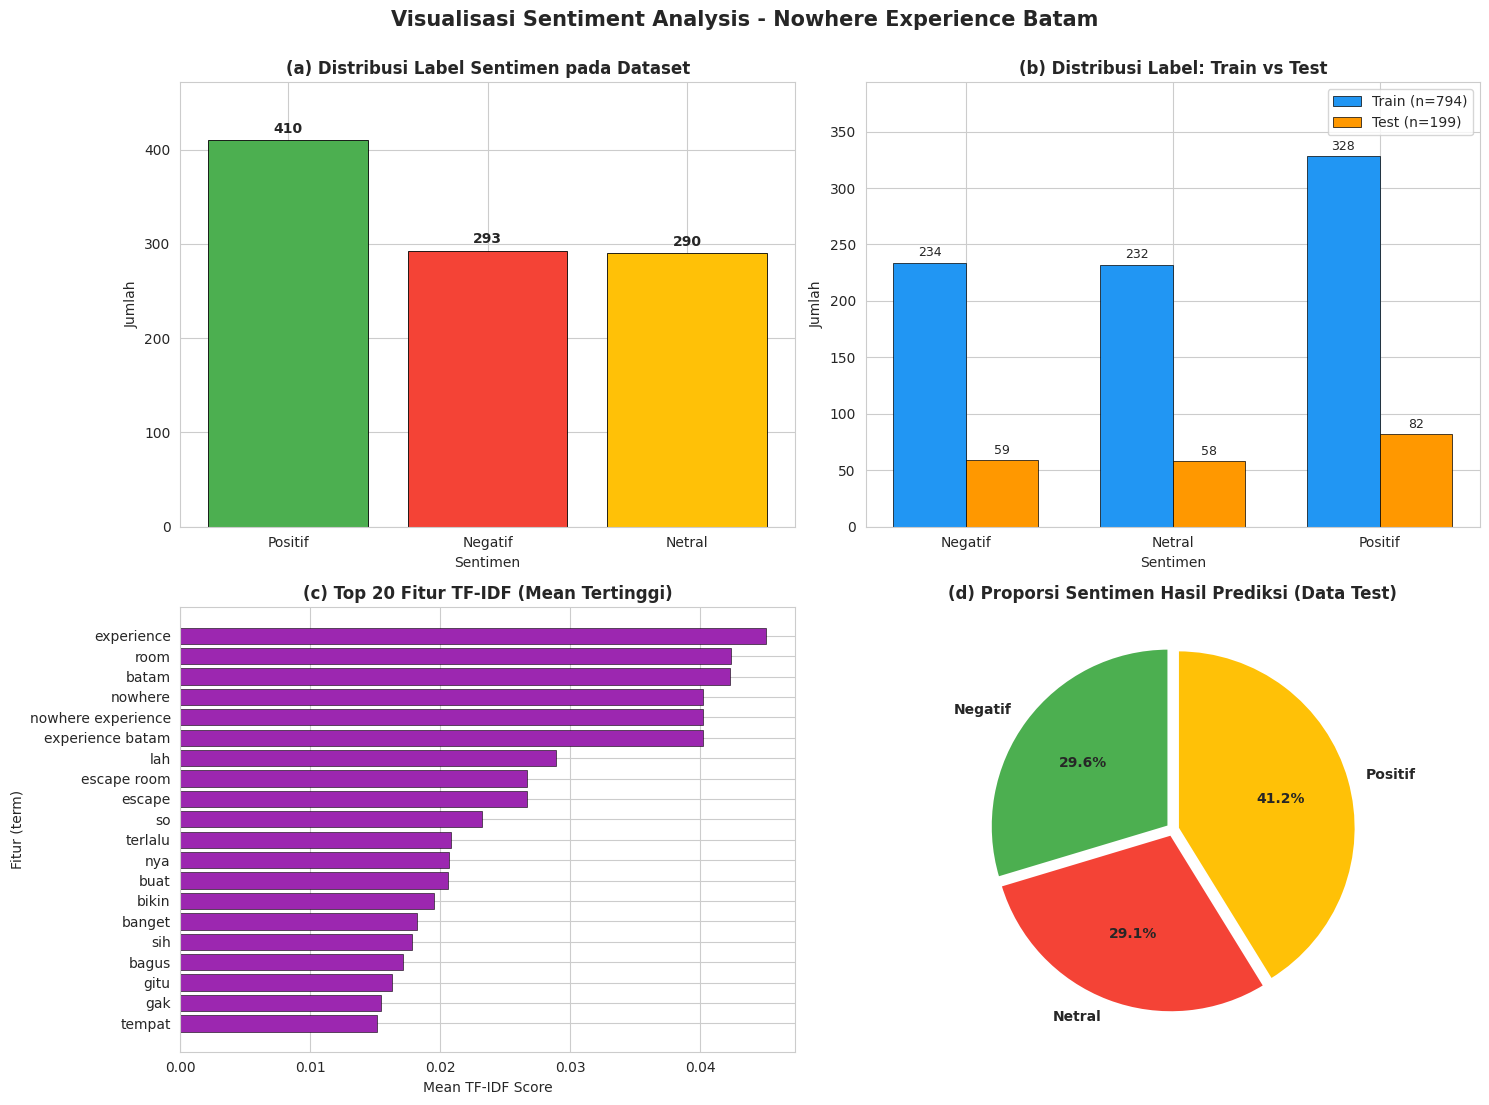


Visualisasi 2x2 berhasil ditampilkan!


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle("Visualisasi Sentiment Analysis - Nowhere Experience Batam",
             fontsize=15, fontweight="bold", y=1.00)

ax1 = axes[0, 0]
counts = df["sentimen"].value_counts()
colors_a = ["#4CAF50", "#F44336", "#FFC107"]
bars = ax1.bar(counts.index, counts.values, color=colors_a, edgecolor="black", linewidth=0.6)
ax1.set_title("(a) Distribusi Label Sentimen pada Dataset",
              fontsize=12, fontweight="bold")
ax1.set_xlabel("Sentimen")
ax1.set_ylabel("Jumlah")
for bar, val in zip(bars, counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             str(val), ha="center", va="bottom", fontweight="bold")
ax1.set_ylim(0, max(counts.values) * 1.15)

ax2 = axes[0, 1]
train_dist = pd.Series(y_train).value_counts().reindex(labels_order)
test_dist = pd.Series(y_test).value_counts().reindex(labels_order)
x_pos = np.arange(len(labels_order))
width = 0.35
bars1 = ax2.bar(x_pos - width/2, train_dist.values, width,
                 label=f"Train (n={len(y_train)})", color="#2196F3",
                 edgecolor="black", linewidth=0.5)
bars2 = ax2.bar(x_pos + width/2, test_dist.values, width,
                 label=f"Test (n={len(y_test)})", color="#FF9800",
                 edgecolor="black", linewidth=0.5)
ax2.set_title("(b) Distribusi Label: Train vs Test",
              fontsize=12, fontweight="bold")
ax2.set_xlabel("Sentimen")
ax2.set_ylabel("Jumlah")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(labels_order)
ax2.legend()
for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2, h + 3, str(int(h)),
                 ha="center", va="bottom", fontsize=9)
ax2.set_ylim(0, max(train_dist.max(), test_dist.max()) * 1.20)


ax3 = axes[1, 0]
mean_tfidf = np.asarray(X_tfidf.mean(axis=0)).flatten()
top20_idx = mean_tfidf.argsort()[-20:][::-1]
top20_feats = [feature_names[i] for i in top20_idx]
top20_vals = mean_tfidf[top20_idx]
ax3.barh(top20_feats[::-1], top20_vals[::-1], color="#9C27B0",
         edgecolor="black", linewidth=0.4)
ax3.set_title("(c) Top 20 Fitur TF-IDF (Mean Tertinggi)",
              fontsize=12, fontweight="bold")
ax3.set_xlabel("Mean TF-IDF Score")
ax3.set_ylabel("Fitur (term)")

ax4 = axes[1, 1]
pred_dist = pd.Series(y_pred).value_counts().reindex(labels_order)
colors_d = ["#4CAF50", "#F44336", "#FFC107"]
wedges, texts, autotexts = ax4.pie(
    pred_dist.values, labels=pred_dist.index, autopct="%1.1f%%",
    colors=colors_d, startangle=90, explode=(0.03, 0.03, 0.03),
    textprops={"fontsize": 10, "fontweight": "bold"},
    wedgeprops={"edgecolor": "white", "linewidth": 1.5}
)
ax4.set_title("(d) Proporsi Sentimen Hasil Prediksi (Data Test)",
              fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

print("\nVisualisasi 2x2 berhasil ditampilkan!")